# Week 8: Solution

The file [`S089R03.csv`](../files/S089R03.csv) contains the EEG recording of a patient during a motor task. 

In [1]:
import pandas as pd

df = pd.read_csv('../files/S089R03.csv')

## Part 1: The discrete Fourier transform

**Goal:** Recall the DFT.

1. For now, let us focus on the time series of sensor `Af7.`. 
   Using the script you created in the hands on of [this course](https://dls.hevs.ch/ts/week06), compute the DFT of the column `Af7.` from the EEG data. 

Here's the script:

In [2]:
import numpy as np

def my_DFT(X):
    N = len(X)

    if N%2 == 0:
        X = X[:-1]
        N -= 1
    
    F = np.fft.fft(X)

    myF = np.array([F[0].real/np.sqrt(N),])

    for k in range(1,int((N+1)/2)):
        myF = np.append(myF, F[k].real*np.sqrt(2/N))
        myF = np.append(myF, F[k].imag*np.sqrt(2/N))

    return myF

def my_DFT_amplitude(X):
    N = len(X)

    if N%2 == 0:
        X = X[:-1]
        N -= 1
    
    F = np.fft.fft(X)

    myF = np.array([F[0].real/np.sqrt(N),])

    for k in range(1,int((N+1)/2)):
        myF = np.append(myF, np.sqrt((F[k].real*np.sqrt(2/N))**2 + (F[k].imag*np.sqrt(2/N))**2))

    return myF

Let us compute the DFT:

In [3]:
X = df['Af7.']

Xt = my_DFT(X)

2. Plot the coefficient $c_k$ and $s_k$ of the DFT as functions of $k$.

28863


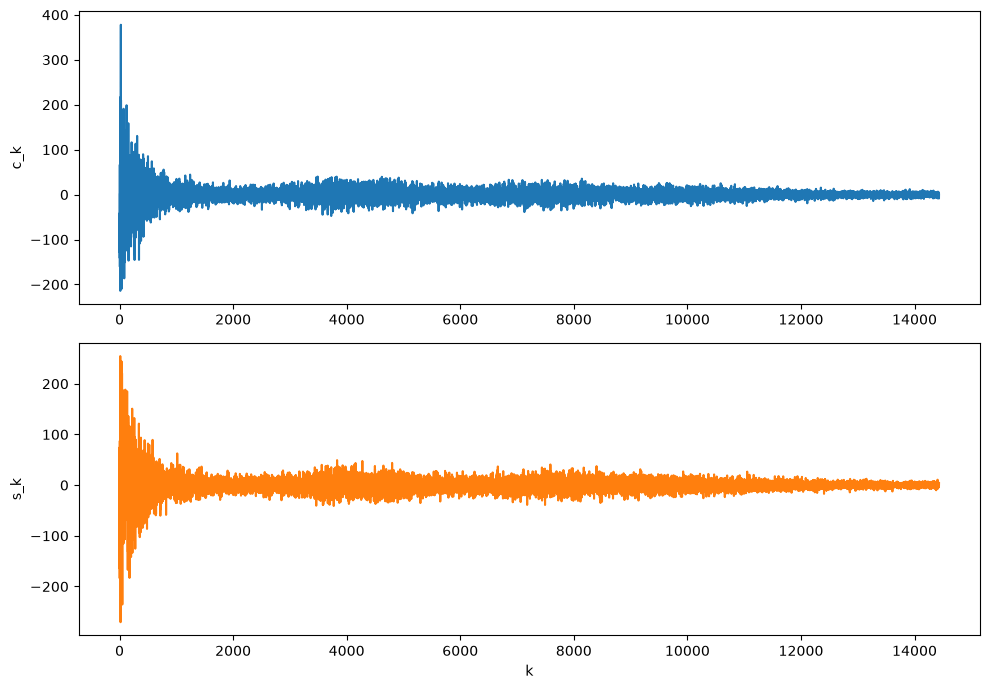

In [4]:
import matplotlib.pyplot as plt

N = len(Xt)

c = np.insert(Xt[1::2], 0, Xt[0])
s = Xt[2::2]

print(N)

fig, ax = plt.subplots(2,1,figsize=(10,7))

ax[0].plot(np.arange((N+1)/2), c, color='C0')
ax[1].plot(np.arange(1,(N+1)/2), s, color='C1')

ax[0].set_ylabel('c_k')
ax[1].set_xlabel('k')
ax[1].set_ylabel('s_k')

plt.tight_layout()
plt.show()

## Part 2: The spectrogram

**Goal:** Build a spectrogram (interpretation will be left for next class).

The idea of a spectrogram is to compute the DFT of a signal on multiple, consecutive time intervals. 

3. Compute again the DFT of column `Af7.`, but only on the first 3001 time steps. 
   Only keep the coefficients $c_k$ for now. 

In [5]:
Xt = my_DFT(X[range(3001)])[1::2]

4. For the same column, compute the DFT for time steps from 500 to 3501. 
   And for time steps 1000 to 4001. 
   Repeat this process as many times as possible and store all the $c_k$ coefficents in a table. 
   At each repetition, you compute the DFT of a time series of length 3001 time steps and that starts 500 time steps after the previous one. 
   You should end up with a table with 1501 rows and 51 columns. 

In [6]:
spectrogram = np.abs(Xt)

i0 = 500

while i0+3001 < len(X):
   spectrogram = np.column_stack([spectrogram, np.abs(my_DFT(X[range(i0,i0+3001)])[1::2])])
   i0 += 500

5. Using the `contourf` function of `matplotlib.pyplot`, provide a graphical representation of the obtained table. 
   This is a spectrogram. 

*Remark: You may want to use the logarithm of the values in your table to emphasize the smaller values.*

6. The spectrogram built at the previous point represents three dimensions (x-axis, y-axis, color scale). 
   What should be the labels of these different dimensions?

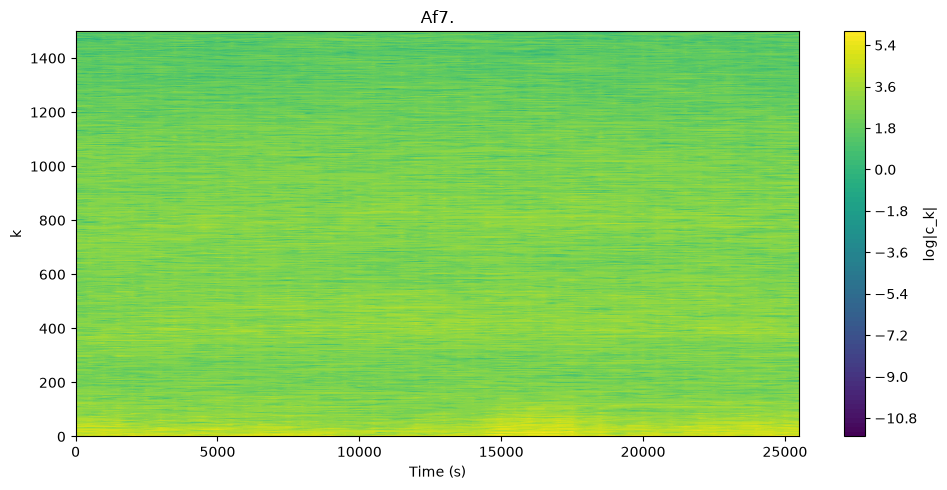

In [7]:
fig, ax = plt.subplots(figsize=(10,5))

f = ax.contourf(np.log(np.abs(spectrogram)), 100)
ax.set_title('Af7.')
ax.set_xticks([0,10,20,30,40,50],[0,5000,10000,15000,20000,25000])
ax.set_xlabel('Time (s)')
ax.set_ylabel('k')
fig.colorbar(f, label='log|c_k|')

plt.tight_layout()
plt.show()

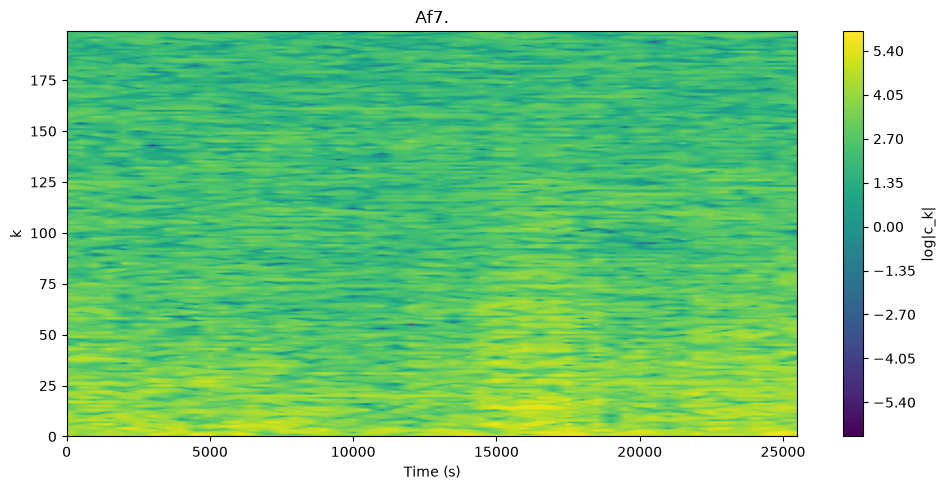

In [8]:
fig, ax = plt.subplots(figsize=(10,5))

f = ax.contourf(np.log(np.abs(spectrogram[:200,:])), 100)
ax.set_title('Af7.')
ax.set_xticks([0,10,20,30,40,50],[0,5000,10000,15000,20000,25000])
ax.set_xlabel('Time (s)')
ax.set_ylabel('k')
fig.colorbar(f, label='log|c_k|')

plt.tight_layout()
plt.show()

7. Gather steps 3-5 into a script and represent the spectrograms for colums `Fp1.`, `Fp2.`, `Iz..`, `Oz..`, and `T8..`. 

*Remark: In the next class, we will see how to interpret the content of the DFT and of the spectrogram.*

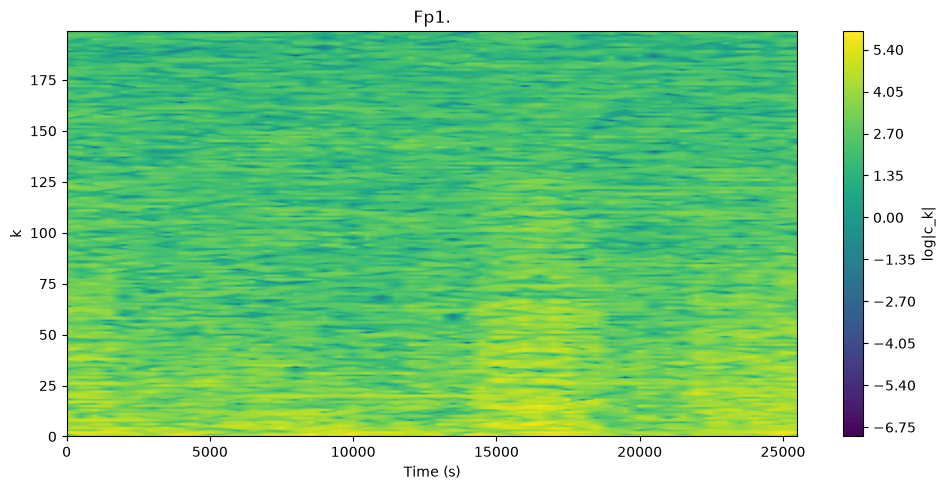

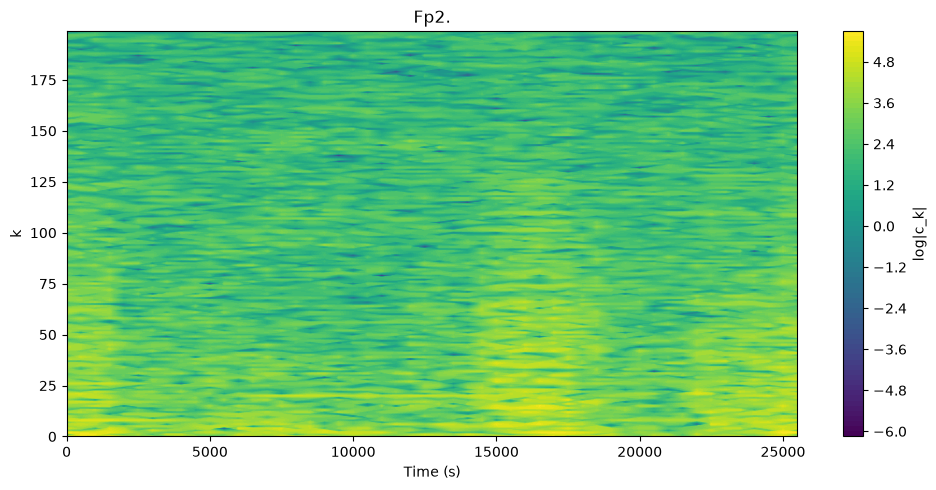

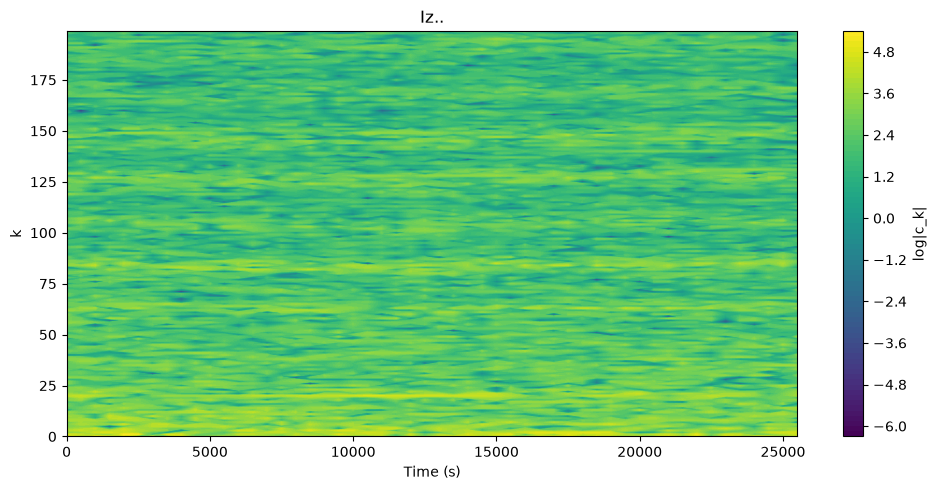

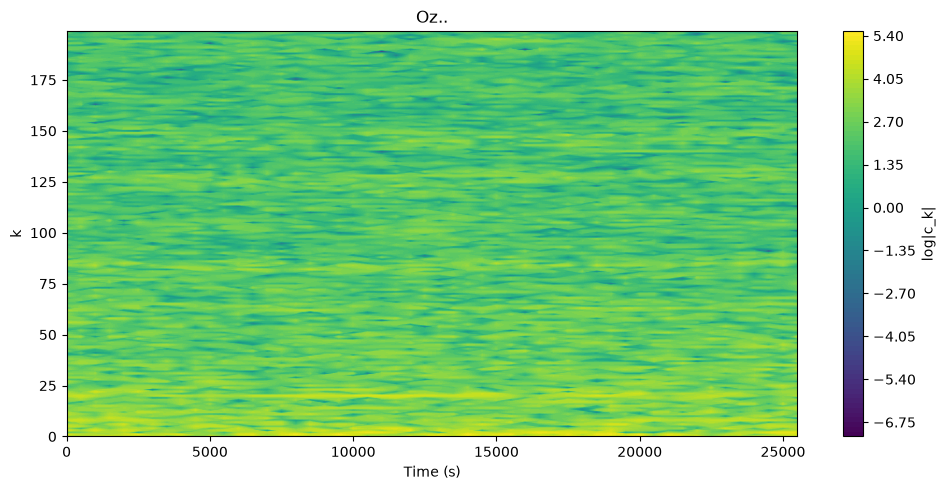

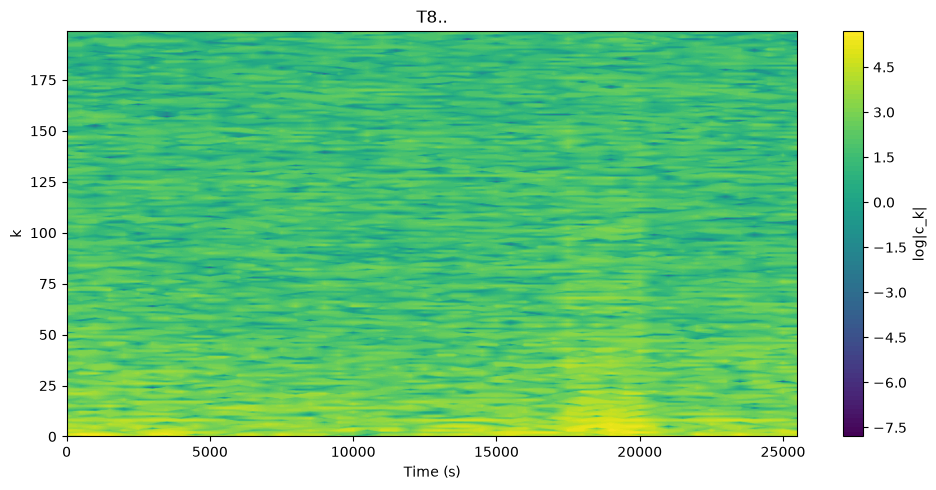

In [9]:
for sensor in ['Fp1.', 'Fp2.', 'Iz..', 'Oz..', 'T8..']:
    X = df[sensor]
    Xt = my_DFT(X[range(3001)])[1::2]

    spectrogram = Xt

    i0 = 500

    while i0+3001 < len(X):
        spectrogram = np.column_stack([spectrogram, np.abs(my_DFT(X[range(i0,i0+3001)])[1::2])])
        i0 += 500

    fig, ax = plt.subplots(figsize=(10,5))

    f = ax.contourf(np.log(np.abs(spectrogram[:200,:])), 100)
    ax.set_title(sensor)
    ax.set_xticks([0,10,20,30,40,50],[0,5000,10000,15000,20000,25000])
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('k')
    
    plt.colorbar(f, label='log|c_k|')

    plt.tight_layout()
    plt.show()